In [1]:
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import statsmodels.api as sm
from scipy.stats import f
import pandas as pd
import numpy as np

Problem 1

Sixteen batches of plastic were made, and from each batch one test item was molded. Each test item was randomly assigned to one of the four predetermined time levels, and the hardness was measured after the assigned elapsed time. The results are shown below; X is the elapsed time in hours, and Y is hardness in Brinell units. Assume the first-order regression model (1.1) is appropriate ((2.1) in the notes).

In [2]:
# i) Estimate the change in the mean hardness when the elapsed time increases by one hour. Use a 99 percent confidence interval. Interpret your interval estimate.

y = np.array([199.0, 205.0, 196.0, 200.0, 218.0, 220.0, 215.0, 223.0, 237.0, 234.0, 235.0, 230.0, 250.0, 248.0, 253.0, 246.0])
x = np.array([16, 16, 16, 16, 24, 24, 24, 24, 32, 32, 32, 32, 40, 40, 40, 40])
x_with_constant = sm.add_constant(x)

df = len(x)-2
lm = sm.OLS(y, x_with_constant).fit()
B1 = lm.params[1]
B1

np.float64(2.0343749999999985)

In [3]:
intervals_99 = lm.conf_int(alpha=0.01)[1]
intervals_99

array([1.76528689, 2.30346311])

Over the long run through repeated random sampling, the true value of β1 will be contained in 99% of the confidence intervals calculated from each sample. We are 99% confident that the true mean hardness of the plastic increases by between 1.7653 and 2.3035 Brinell units for every additional hour of elapsed time.

In [4]:
# ii) The plastic manufacturer has stated that the mean hardness should increase by 2 Brinell units per hour. Conduct a two-sided test to decide whether this standard is being satisfied; use α=0.01

alpha = 0.01
hypothesis = "x = 2"
df = pd.DataFrame({"x": x, "y": y})
model = smf.ols("y ~ x", data=df).fit()
t_test_results = model.t_test(hypothesis)
t_test_results.summary(alpha=alpha)

,coef,std err,t,P>|t|,[0.005,0.995]
c0,2.0344,0.090,0.380,0.709,1.765,2.303


In [5]:
t_test_results.pvalue < alpha

np.False_

The null hypothesis states that β1 = 2.

p-value is greater than alpha, we fail to reject the null hypothesis. The data do not provide sufficient evidence that the mean hardness increase differs from 2 Brinell units per hour. However, failing to reject does not prove the manufacturer’s claim is true.

In [6]:
# iii) Set up the ANOVA table.

anova_table = sm.stats.anova_lm(model, typ=1)
anova_table.loc["Total", "df"] = model.nobs - 1
anova_table.loc["Total", "sum_sq"] = model.centered_tss
anova_table

,df,sum_sq,mean_sq,F,PR(>F)
x,1.0,5297.5125,5297.512500,506.506232,2.158814e-12
Residual,14.0,146.4250,10.458929,NaN,NaN
Total,15.0,5443.9375,NaN,NaN,NaN


In [7]:
# iv) Test by means of an F-test whether or not there is a linear association between the hardness of the plastic and the elapsed time. Use α=0.01

f_statistic = model.fvalue
f_statistic

np.float64(506.50623185931335)

In [8]:
f_p_value = model.f_pvalue
f_p_value

np.float64(2.158813682525074e-12)

In [9]:
f_p_value < alpha

np.True_

The null hypothesis states that there is no linear association. p-value is less than alpha, we reject the null hypothesis. The model is statistically significant.

v) Does t^2_calc from part [ii] equal f_calc from part [iv]? Explain why this identity holds or does not hold.

t^2_calc from part [ii] does not equal f_calc from part [iv] because for part [ii] H0: β1 = 2 and for part [iv] H0: β1 = 0.

In [10]:
# vi) Construct 95% Bonferroni joint confidence intervals for estimating both the true intercept β0 and the true slope β1.

alpha = 0.05
num_params = 2
bonferroni_ci = lm.conf_int(alpha=alpha/num_params)
bonferroni_ci

array([[161.93201373, 175.26798627],
       [  1.8075255 ,   2.2612245 ]])

In [11]:
# vii) Construct 95% Bonferroni joint confidence intervals for predicting the true average hardness corresponding to elapsed times 20, 28 and 36 hours.

new = np.array([20, 28, 36])
x_new = sm.add_constant(new)
m = len(x_new)

predictions = lm.get_prediction(x_new)
bonferroni = predictions.summary_frame(alpha=alpha / m)
bonferroni[["mean_ci_lower", "mean_ci_upper"]]

,mean_ci_lower,mean_ci_upper
0,206.339482,212.235518
1,223.365177,227.759823
2,238.889482,244.785518


Problem 2

In [12]:
# i)

rand_gen = np.random.default_rng(0)
B1_0 = 0
B0 = 10
sigma = 3
n = 30

X = rand_gen.uniform(0, 100, n)
X = sm.add_constant(X)
f_statistic_list = np.zeros(10000)

for i in range(10000):
    Y = rand_gen.normal(0, sigma, n) + B0
    m = sm.OLS(Y, X).fit()
    f_statistic_list[i] = m.fvalue

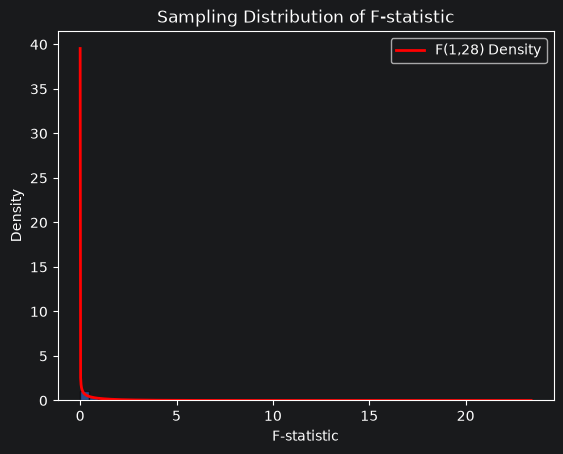

In [13]:
# ii) From the simulated sampling distribution, plot a histogram and overlay the correct F-density on the histogram. Adjust the bin-size to breaks=50 in the histogram. Overlay the F-density in red.

plt.hist(f_statistic_list, bins=50, density=True, edgecolor='black', alpha=0.6)

x_values = np.linspace(0.0001, f_statistic_list.max(), 1000)
f_density = f.pdf(x_values, dfn=1, dfd=n-2)
plt.plot(x_values, f_density, color='red', linewidth=2, label='F(1,28) Density')

plt.xlabel('F-statistic')
plt.ylabel('Density')
plt.title('Sampling Distribution of F-statistic')
plt.legend()
plt.show()

In [14]:
# iii) Compute the 95th percentile of both the simulated sampling distribution and the correct F-distribution. Compare these values.

simulated_95 = np.percentile(f_statistic_list, 95)
theoretical_95 = f.ppf(0.95, dfn=1, dfd=n-2)

print(f"Simulated 95th percentile: {simulated_95}")
print(f"Theoretical 95th percentile: {theoretical_95}")

Simulated 95th percentile: 4.426949862090172
Theoretical 95th percentile: 4.195971818557765


The simulated 95th percentile is 4.42695, while the theoretical 95th percentile is 4.19597. These values are quite close with the difference attributable to random sampling variation in the 10,000 simulations. This supports the result that the f-statistic follows an F(1,28) distribution under the null hypothesis.

Problem 4

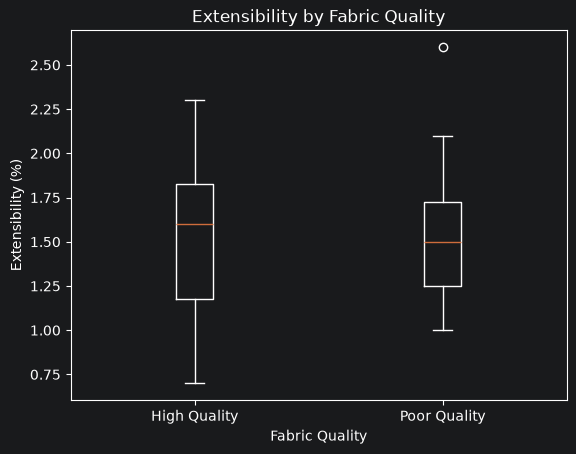

In [15]:
# i) Create an appropriate graphic to visualize the relationship between extensibility and quality. Do you think there is a relationship between extensibility and quality? Make sure to label the plot.

H = [ 1.2, 0.9, 0.7, 1.0, 1.7, 1.7, 1.1, 0.9, 1.7, 1.9, 1.3, 2.1, 1.6, 1.8, 1.4, 1.3, 1.9, 1.6, 0.8, 2.0, 1.7, 1.6, 2.3, 2.0]
P = [1.6, 1.5, 1.1, 2.1, 1.5, 1.3, 1.0, 2.6]

plt.boxplot([H, P], tick_labels=["High Quality", "Poor Quality"])
plt.xlabel("Fabric Quality")
plt.ylabel("Extensibility (%)")
plt.title("Extensibility by Fabric Quality")
plt.show()

There is not a strong relationship between extensibility and quality as the poor and high quality groups have a very similar mean where both are somewhat symmetrically distributed around. The 2 distributions have significant overlap.

In [16]:
# ii) Using the indicator variable run a regression analysis to test if the average fabric extensibility diﬀers per group.

Y = np.array(H + P)
I = np.array([1] * len(H) + [0] * len(P))
I = sm.add_constant(I)

binary_model = sm.OLS(Y, I).fit()
binary_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.006
Model:                            OLS   Adj. R-squared:                 -0.027
Method:                 Least Squares   F-statistic:                    0.1734
Date:                Sat, 24 Oct 2026   Prob (F-statistic):              0.680
Time:                        17:36:44   Log-Likelihood:                -19.921
No. Observations:                  32   AIC:                             43.84
Df Residuals:                      30   BIC:                             46.77
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.5875      0.165      9.641      0.000       1.251       1.924
x1            -0.0792      0.190     -0.416      0.680      -0.467       0.309
==============================================================================
Omnibus:                        0.690   Durbin-Watson:                   1.677
Prob(Omnibus):                  0.708   Jarque-Bera (JB):                0.719
Skew:                           0.124   Prob(JB):                        0.698
Kurtosis:                       2.309   Cond. No.                         3.78
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [17]:
binary_model.f_pvalue > 0.05

np.True_

There is a small difference in average extensibility, poor-quality fabric has a slightly higher estimated mean extensibility than high-quality fabric. At alpha = 0.05 we fail to reject the null hypothesis of β1 = 0 given the p-value of 0.68. There is insufficient evidence to conclude that mean extensibility differs between high-quality and poor-quality fabrics.